# 03 · Dos líneas base y cinco familias

Las dos bases se ejecutan primero para t+3. Se usa AP (PR-AUC no interpolada), misma preparación y CV para todas las familias. Defaults sklearn; solo se fija semilla. La regla estacional reproduce PSet 1 y su score no es una probabilidad calibrada.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.datos import DATA, DOCS, EVIDENCE
from src.datos import execute
HAS_DATA = (DATA / "obt.parquet").exists()
display(Markdown("**OBT real local disponible**" if HAS_DATA else
    "**PENDIENTE:** faltan credenciales Snowflake válidas y snapshot. Este notebook no contiene resultados empíricos del ECU 911."))


**OBT real local disponible**

## Comparación registrada

Familias: logística (lineal), random forest (bagging), hist gradient boosting (boosting), MLP (red neuronal), GaussianNB (probabilístico). Train AP, CV media±SD, brecha y tiempo permiten diagnosticar generalización. No se garantiza superar ambas bases.

INICIO baseline t+3 dummy {}


2026/11/11 22:51:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN baseline t+3 dummy: AP_CV=0.07900 ± 0.00422; ajuste=2.0s
🏃 View run baseline-t3-dummy at: http://127.0.0.1:5001/#/experiments/1/runs/d8a88c6f91904c5f81a74a7b3c0b80ca
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
INICIO baseline t+3 estacional {}


2026/11/11 22:51:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN baseline t+3 estacional: AP_CV=0.19489 ± 0.01584; ajuste=0.0s
🏃 View run baseline-t3-estacional at: http://127.0.0.1:5001/#/experiments/1/runs/ba152e1f2ac646e1a9d4345eeb56bb64
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
INICIO candidato t+3 logistica {}


2026/11/11 22:51:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (7 outputs left out)

2026/11/11 23:00:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN candidato t+3 gaussian_nb: AP_CV=0.11964 ± 0.00718; ajuste=6.3s
🏃 View run candidato-t3-gaussian_nb at: http://127.0.0.1:5001/#/experiments/1/runs/b6ae5bc1c038490d8e302ee7315b40b7
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


,horizon,phase,name,train_ap,cv_ap_mean,cv_ap_std,gap,learning_rate,fit_seconds,warnings
0,3,baseline,dummy,0.082132,0.078997,0.004223,0.003135,NA,2.013871,0
1,3,baseline,estacional,0.178287,0.194888,0.015843,-0.016601,NA,0.016038,0
2,3,candidato,logistica,0.199895,0.180774,0.024387,0.019121,NA,5.857485,0
3,3,candidato,random_forest,1.000000,0.210112,0.056095,0.789888,NA,90.924812,0
4,3,candidato,hist_boosting,0.301220,0.213288,0.049684,0.087932,0.1,18.283618,0
5,3,candidato,mlp,0.453169,0.159505,0.043024,0.293664,0.001,427.337394,4
6,3,candidato,gaussian_nb,0.130661,0.119639,0.007181,0.011022,NA,6.272934,0


,horizon,name,beats_both_baselines
2,3,logistica,False
3,3,random_forest,True
4,3,hist_boosting,True
5,3,mlp,False
6,3,gaussian_nb,False


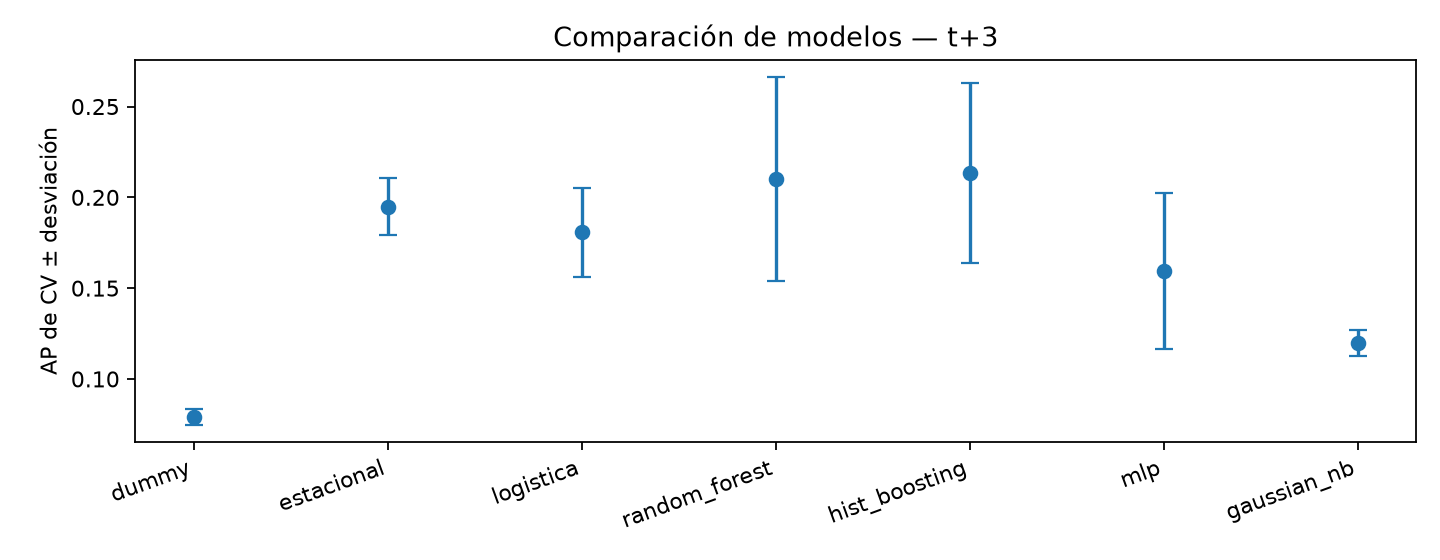

In [2]:
if HAS_DATA:
    rows = execute("candidatos")
    results = pd.DataFrame(rows)
    display(results[["horizon", "phase", "name", "train_ap", "cv_ap_mean", "cv_ap_std", "gap", "learning_rate", "fit_seconds", "warnings"]])
    display(results.loc[results.phase.eq("candidato"), ["horizon", "name", "beats_both_baselines"]])
    from src.datos import plot_candidates
    display(Image(filename=str(plot_candidates(rows))))


## Evidencia de aporte de features

Ablación de ratios con regresión logística y los mismos folds. Una diferencia inferior a la SD no prueba aporte; se conserva el resultado negativo si ocurre.

In [3]:
if HAS_DATA:
    display(pd.DataFrame(execute("ablacion")))

INICIO ablacion t+3 logistica {}


2026/11/11 23:01:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN ablacion t+3 logistica: AP_CV=0.17939 ± 0.02656; ajuste=8.7s
🏃 View run ablacion-t3-logistica at: http://127.0.0.1:5001/#/experiments/1/runs/7ec42050697041efb83140876607f0b0
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


,horizon,run_id,without_ap,with_ap,delta,exceeds_std
0,3,7ec42050697041efb83140876607f0b0,0.179391,0.180774,0.001383,False


## LLM mediante prompting

El caso sí puede plantearse como clasificación tabular zero-shot. Se prueba en una muestra del último fold, con salidas JSON y sin fechas/nombres exactos. Se compara con las predicciones OOF de las mismas filas. No se usa hold-out ni se incorpora una muestra pequeña al ranking de CV completa. Se usa `qwen2.5:1.5b` en Ollama local, sin API key; la evaluación requiere la OBT real.

In [4]:
if HAS_DATA:
    display(execute("llm"))
else:
    display(Markdown("**Evaluación LLM pendiente:** Ollama local con qwen2.5:1.5b está configurado; falta el snapshot real. El prompt está en src/datos.py (llm_trial)."))

🏃 View run prompting-t3 at: http://127.0.0.1:5001/#/experiments/1/runs/9807c2b5c5aa479699a207200c0a7365
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


[{'horizon': 3,
  'run_id': '9807c2b5c5aa479699a207200c0a7365',
  'metrics': {'ap': 0.09,
   'precision': 0.0,
   'recall': 0.0,
   'tn': 91,
   'fp': 0,
   'fn': 9,
   'tp': 0,
   'cost_per_1000': 450.0,
   'alert_rate': 0.0},
  'rows': 100,
  'comparison_same_rows': [{'name': 'dummy',
    'ap': 0.09,
    'precision': 0.0,
    'recall': 0.0,
    'tn': 91,
    'fp': 0,
    'fn': 9,
    'tp': 0,
    'cost_per_1000': 450.0,
    'alert_rate': 0.0},
   {'name': 'estacional',
    'ap': 0.23499687436001504,
    'precision': 0.5,
    'recall': 0.1111111111111111,
    'tn': 90,
    'fp': 1,
    'fn': 8,
    'tp': 1,
    'cost_per_1000': 410.0,
    'alert_rate': 0.02},
   {'name': 'logistica',
    'ap': 0.30226926857361647,
    'precision': 0.25,
    'recall': 0.1111111111111111,
    'tn': 88,
    'fp': 3,
    'fn': 8,
    'tp': 1,
    'cost_per_1000': 430.0,
    'alert_rate': 0.04},
   {'name': 'random_forest',
    'ap': 0.3197604459899541,
    'precision': 0.2,
    'recall': 0.111111111111111